<a href="https://colab.research.google.com/github/masumeaslanii/ML2026/blob/main/The_7th_Session.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import time
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, Subset
from torchvision import transforms, datasets

# What do we do for implementing 2D CNN on our Dataset?

* Connecting to our Drive
* Loading our dataset
* Creating batch sets
* Definig device
* Designing our CNN model
* Train and validation loop
* Saving and Loading our model
* predicting on unseen data

> Note: This library `google.colab` is specific to Google Colab and cannot be used directly in local environments such as VS Code.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Data Preprocessing and Transformations

In this section, we define preprocessing operations to prepare images before feeding them into the CNN model.

- **RandomCrop:** Randomly crops a 32×32 region after adding 4 pixels of padding around the image. It helps the model generalize better by exposing it to objects at slightly different positions, making it more robust to small spatial shifts and reducing overfitting.
- **RandomHorizontalFlip:** Randomly flips images horizontally with a probability of 0.5.
- **ToTensor**: Converts the image into a PyTorch tensor, changes its dimension order from `(H, W, C)` to `(C, H, W)`, and scales pixel values from `[0, 255]` to `[0, 1]`.
- **Normalization:** Scales pixel values from [0, 1] to approximately [-1, 1] using the specified mean and standard deviation.

We use `transforms.Compose()` to combine multiple transformations into a single pipeline.

**Training Transform:** Applies data augmentation (RandomCrop and RandomHorizontalFlip), followed by tensor conversion and normalization.

**Test Transform:** Applies only tensor conversion and normalization, without data augmentation. This allows us to evaluate the model on unmodified images and measure its performance more realistically.
> Data Augmentation Increases the diversity of training samples and helps the model generalize better to unseen data. It is typically applied only to training data, not validation or test data.

> Note: Since CIFAR images have three color channels (RGB), mean and standard deviation each contain three values. Using `0.5` for all three channels is a simple and common normalization choice, but these are not necessarily the dataset's actual statistics.

In [3]:
mean, std = (0.5071, 0.4865, 0.4409), (0.2673, 0.2564, 0.2762)

train_transform = transforms.Compose([transforms.RandomCrop(32, padding= 4),
                                      transforms.RandomHorizontalFlip(),
                                      transforms.ToTensor(),
                                      transforms.Normalize(mean= mean, std= std)])


test_transform = transforms.Compose([transforms.ToTensor(),
                                    transforms.Normalize(mean= mean, std= std)])

## Loading CIFAR-100 Dataset

In this section, we load the CIFAR-100 dataset using `torchvision.datasets.CIFAR100()`.

- **DATA_DIR:** Specifies the directory where the dataset is stored.
- **Training Dataset:** Loads the 50,000 training images using `train=True` and applies training transformations, including data augmentation.
- **Validation Dataset:** Loads the same 50,000 training images using `train=True`, but applies only tensor conversion and normalization. We will later use `Subset` to select 5,000 images for validation.
- **Test Dataset:** Loads the 10,000 test images using `train=False`, without data augmentation. These images are reserved for final model evaluation.

**Note:** CIFAR-100 provides two original splits: 50,000 training images and 10,000 test images. It does not include a separate validation set, so we create one from the training data.

### Dataset Summary

| Dataset | Images | Augmentation | Purpose |
|---|---:|---|---|
| Training | 50,000 initially | Yes | Model training |
| Validation | 5,000 selected | No | Model evaluation during development |
| Test | 10,000 | No | Final model evaluation |

In [4]:
DATA_DIR= '/content/drive/MyDrive/CIFAR100_Dataset'

traindata = datasets.CIFAR100(root= DATA_DIR,
                              train= True,
                              download= False,
                              transform= train_transform)

validationdata = datasets.CIFAR100(root= DATA_DIR,
                              train= True,
                              download= False,
                              transform= test_transform)

testdata = datasets.CIFAR100(root= DATA_DIR,
                              train= False,
                              download= False,
                              transform= test_transform)

In [5]:
traindata

Dataset CIFAR100
    Number of datapoints: 50000
    Root location: /content/drive/MyDrive/CIFAR100_Dataset
    Split: Train
    StandardTransform
Transform: Compose(
               RandomCrop(size=(32, 32), padding=4)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
               Normalize(mean=(0.5071, 0.4865, 0.4409), std=(0.2673, 0.2564, 0.2762))
           )

In [6]:
validationdata

Dataset CIFAR100
    Number of datapoints: 50000
    Root location: /content/drive/MyDrive/CIFAR100_Dataset
    Split: Train
    StandardTransform
Transform: Compose(
               ToTensor()
               Normalize(mean=(0.5071, 0.4865, 0.4409), std=(0.2673, 0.2564, 0.2762))
           )

In [7]:
testdata

Dataset CIFAR100
    Number of datapoints: 10000
    Root location: /content/drive/MyDrive/CIFAR100_Dataset
    Split: Test
    StandardTransform
Transform: Compose(
               ToTensor()
               Normalize(mean=(0.5071, 0.4865, 0.4409), std=(0.2673, 0.2564, 0.2762))
           )

- `traindata[49999]`: Retrieves the sample at index `49999`, returning a tuple `(image, label)`.
- `traindata[49999][0]`: Retrieves the image.
- `traindata[49999][1]`: Retrieves the corresponding class label.
- `type(traindata[49999][0])`: Returns `torch.Tensor`.

**Why?** Because `ToTensor()` converts the image into a PyTorch Tensor.

**Note:** Random transformations are applied every time a sample is accessed, so the same image may look slightly different each time.

In [8]:
type(traindata[49999][0])

torch.Tensor

`traindata.targets` Returns the labels of all training images. CIFAR-100 has 100 classes, so labels range from `0` to `99`.
- `train_label[49999]` Returns the label of the sample at index `49999`.

In [9]:
train_label = traindata.targets

`traindata.data` Returns the original images without applying any transformations.
- Unlike `traindata[index]`, it does not apply the assigned transform.

In [10]:
train_image = traindata.data

In [11]:
train_image

array([[[[255, 255, 255],
         [255, 255, 255],
         [255, 255, 255],
         ...,
         [195, 205, 193],
         [212, 224, 204],
         [182, 194, 167]],

        [[255, 255, 255],
         [254, 254, 254],
         [254, 254, 254],
         ...,
         [170, 176, 150],
         [161, 168, 130],
         [146, 154, 113]],

        [[255, 255, 255],
         [254, 254, 254],
         [255, 255, 255],
         ...,
         [189, 199, 169],
         [166, 178, 130],
         [121, 133,  87]],

        ...,

        [[148, 185,  79],
         [142, 182,  57],
         [140, 179,  60],
         ...,
         [ 30,  17,   1],
         [ 65,  62,  15],
         [ 76,  77,  20]],

        [[122, 157,  66],
         [120, 155,  58],
         [126, 160,  71],
         ...,
         [ 22,  16,   3],
         [ 97, 112,  56],
         [141, 161,  87]],

        [[ 87, 122,  41],
         [ 88, 122,  39],
         [101, 134,  56],
         ...,
         [ 34,  36,  10],
        

array([[[ 31,  67, 122],
        [ 30,  68, 124],
        [ 31,  69, 126],
        ...,
        [ 32,  70, 129],
        [ 32,  70, 125],
        [ 32,  69, 122]],

       [[ 29,  68, 126],
        [ 28,  69, 128],
        [ 30,  69, 130],
        ...,
        [ 32,  70, 131],
        [ 32,  69, 127],
        [ 31,  69, 124]],

       [[ 30,  67, 126],
        [ 29,  68, 128],
        [ 30,  69, 130],
        ...,
        [ 32,  72, 132],
        [ 31,  70, 130],
        [ 30,  69, 127]],

       ...,

       [[ 39,  41,  76],
        [ 38,  42,  76],
        [ 38,  44,  78],
        ...,
        [ 39,  44,  79],
        [ 38,  42,  77],
        [ 39,  41,  76]],

       [[ 40,  39,  73],
        [ 39,  40,  74],
        [ 39,  41,  76],
        ...,
        [ 39,  41,  76],
        [ 40,  41,  74],
        [ 40,  39,  73]],

       [[ 40,  39,  70],
        [ 40,  39,  71],
        [ 40,  39,  72],
        ...,
        [ 41,  38,  72],
        [ 39,  38,  69],
        [ 40,  37,  67]]], shape=(32, 32, 3), dtype=uint8)
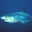

In [12]:
train_image[49999]

In [13]:
train_image[49999].shape

(32, 32, 3)

In [14]:
type(train_image[49999])

numpy.ndarray

array([[[141, 134, 115],
        [167, 160, 142],
        [161, 154, 137],
        ...,
        [ 59,  49,  38],
        [ 44,  34,  23],
        [ 80,  70,  60]],

       [[107,  99,  85],
        [146, 139, 121],
        [153, 147, 124],
        ...,
        [ 40,  30,  18],
        [103,  94,  81],
        [165, 155, 143]],

       [[ 71,  64,  49],
        [112, 105,  87],
        [120, 114,  91],
        ...,
        [ 96,  87,  72],
        [154, 145, 130],
        [180, 170, 155]],

       ...,

       [[119, 112,  94],
        [ 92,  86,  68],
        [ 79,  72,  54],
        ...,
        [147, 138, 121],
        [ 95,  86,  69],
        [ 59,  50,  33]],

       [[130, 122, 104],
        [114, 107,  89],
        [ 84,  77,  59],
        ...,
        [ 71,  62,  45],
        [ 52,  43,  26],
        [ 81,  72,  55]],

       [[141, 133, 115],
        [122, 115,  98],
        [106,  99,  81],
        ...,
        [ 66,  57,  40],
        [ 98,  89,  72],
        [140, 131, 114]]], shape=(32, 32, 3), dtype=uint8)
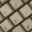

In [15]:
train_image[4999]

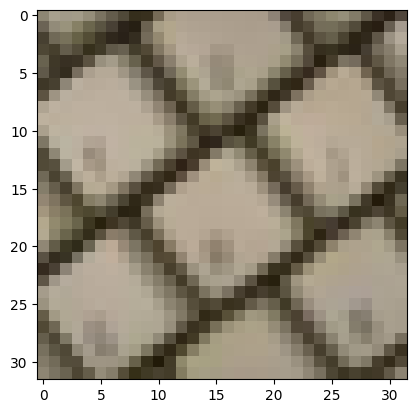

In [16]:
plt.imshow(train_image[4999])

In [17]:
train_image.shape

(50000, 32, 32, 3)

In [18]:
train_image.shape[0]

50000

## Splitting Training and Validation Data

We split the original 50,000 training images into:
- **Training:** 45,000 samples
- **Validation:** 5,000 samples

**Creating a Generator:**
- `torch.Generator()` Creates a random number generator.
- `manual_seed(42)` Ensures reproducibility by generating the same random sequence across runs under the same conditions.

**Generating Random Indices:**
- `torch.randperm()` Generates a random permutation of integers from `0` to `49,999`.
- `generator=generator` Uses our predefined generator and seed.

**Selecting Training Indices:**
- `indices[:45000]` Selects the first 45,000 indices.
- `.tolist()` Converts the Tensor into a Python list.

**Selecting Validation Indices:**
- `indices[45000:]` Selects the remaining 5,000 indices.
- `.tolist()` Converts them into a Python list.

> **Note:** Both subsets are randomly selected without overlap, ensuring that each sample belongs to either the training or validation set.

In [19]:
generator = torch.Generator().manual_seed(42)
indices= torch.randperm(train_image.shape[0], generator= generator)
indices

tensor([37542, 44491,   216,  ..., 40730, 25847, 33082])

In [20]:
train_indices = indices[:45000].tolist()
validaion_indices = indices[45000:].tolist()
type(train_indices)

list

## Creating Training and Validation Subsets

We use `Subset()` to create two smaller datasets from the original datasets using the selected indices.

- **Training Subset:** Selects 45,000 samples from `traindata`, applying `train_transform` (including data augmentation).
- **Validation Subset:** Selects 5,000 samples from `validationdata`, applying `test_transform` (without data augmentation).

> **Important:** The validation subset must be created from `validationdata`, not `traindata`, to ensure that random data augmentation is not applied during validation.

In [21]:
train_data = Subset(traindata, train_indices)
val_data = Subset(validationdata, validaion_indices)

## Creating DataLoaders

`DataLoader()` divides datasets into smaller batches for efficient training and evaluation.

- **batch_size=128:** Processes 128 images per batch. The training set contains 352 batches per epoch.
- **shuffle=True:** Randomly changes the sample order in each epoch to prevent learning from a fixed data order.

**TestLoader:**
Loads 10,000 test images in batches of 128. `shuffle=False` keeps their order unchanged.

**ValidationLoader:**
Loads 5,000 validation images in batches of 128, also with `shuffle=False`.

| DataLoader | Samples | Shuffle |
|---|---:|---|
| TrainLoader | 45,000 | True |
| ValidationLoader | 5,000 | False |
| TestLoader | 10,000 | False |

In [22]:
TrainLoader = DataLoader(train_data, batch_size= 128, shuffle= True)
TestLoader = DataLoader(testdata, batch_size= 128, shuffle= False)
ValidationLoader = DataLoader(val_data, batch_size= 128, shuffle= False)

## Defining device

In [23]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

## Designing our 2D CNN Model

**1. Padding**

Padding adds extra pixels (usually zeros) around the input to control the output dimensions.

- Padding formula:
$$
P = \frac{K-1}{2}
$$

  This preserves the input size when stride = 1 (for odd-sized kernels).

- Example:

  If the input contains 8 pixels and padding = 1:

$$
0 \quad x_1 \quad x_2 \quad x_3 \quad x_4 \quad x_5 \quad x_6 \quad x_7 \quad x_8 \quad 0
$$

  One zero is added to each side.

**2. Stride**

Stride determines how many pixels the filter moves at each step.

- Stride = 1: The filter moves one pixel at a time.
- Stride = 2: The filter moves two pixels at a time, reducing the spatial dimensions.

Using stride = 2 can perform downsampling without requiring a separate pooling layer.

**3. Output Size Formula**

General Formula (with Dilation):
$$
L_{out} = \left\lfloor \frac{L_{in}+2P-D(K-1)-1}{S} \right\rfloor + 1
$$

Simplified Formula (when D = 1):
$$
L_{out} = \left\lfloor \frac{L_{in}-K+2P}{S} \right\rfloor + 1
$$

Where:

- `L_in`: Input length
- `L_out`: Output length
- `K`: Kernel size
- `P`: Padding
- `S`: Stride
- `D`: Dilation


> **Important Notes**
> - When stride = 1 and padding = (K - 1) / 2, the output size remains equal to the input size (for odd-sized kernels).
> - When stride = 2, the output dimensions are approximately halved.
> - Stride = 2 can replace a separate downsampling operation, depending on the architecture.
> - Padding = 0 means no extra pixels are added (Valid Padding).
> - Padding = (K - 1) / 2 with stride = 1 is commonly called Same Padding.


---



**Fully Connected (FC) Layers**

The FC layers receive the features extracted by the Convolutional layers and use them for classification.

- **Flatten:** Converts the feature maps from `(Batch, Channels, Height, Width)` into `(Batch, Features)`. For example: `(128, 256, 4, 4) → (128, 4096)`.

- **Linear(4096, 128):** Combines the 4096 input features into 128 output features using learnable weights and biases.

- **ReLU:** Introduces non-linearity, allowing the network to learn more complex patterns.

- **Dropout(p=0.2):** Randomly disables 20% of neurons during training to reduce overfitting. It is disabled during evaluation.

- **Linear(128, num_classes):** Produces one logit per class. For CIFAR-100, the output contains 100 logits per image.

**Note:** The number of hidden neurons (128) and the Dropout rate (0.2) are design choices and can be adjusted through experimentation.
> Why two layers? The ReLU between them allows the network to learn more complex, non-linear patterns.
> - First Linear (4096 → 128): Combines extracted features into a compact representation.
> - Second Linear (128 → 100): Maps these features to class scores (logits) for classification.



In [24]:
class CNN2D(nn.Module):
  def __init__(self, in_channels, num_classes):
    super(CNN2D, self).__init__()

    self.Blocks = nn.Sequential(nn.Conv2d(in_channels= in_channels, out_channels= 64, kernel_size= 3, padding= 1, stride= 1),
                              nn.BatchNorm2d(num_features= 64),
                              nn.ReLU(inplace= False),
                              nn.MaxPool2d(kernel_size= 2, stride= 2),

                              nn.Conv2d(in_channels= 64, out_channels= 128, kernel_size= 3, padding= 1, stride= 1),
                              nn.BatchNorm2d(num_features= 128),
                              nn.ReLU(inplace= False),
                              nn.MaxPool2d(kernel_size= 2, stride= 2),

                              nn.Conv2d(in_channels= 128, out_channels= 256, kernel_size= 3, padding= 1, stride= 1),
                              nn.BatchNorm2d(num_features= 256),
                              nn.ReLU(inplace= False),
                              nn.MaxPool2d(kernel_size= 2, stride= 2))

    self.FC = nn.Sequential(nn.Flatten(),
                            nn.Linear(256*4*4, 128),
                            nn.ReLU(),
                            nn.Dropout(p= 0.2),
                            nn.Linear(128, num_classes))
  def forward(self, x):
    x = self.Blocks(x)
    x = self.FC(x)

    return x

- `torch.manual_seed(42)`: Sets the random seed to make experiments more reproducible.

- `CNN2D(3, 100)`: Creates a CNN2D model with 3 input channels (RGB) and 100 output classes.

- `.to(device)`: Moves the model to the specified device (CPU or GPU).

In [25]:
torch.manual_seed(42)

CNN_Model = CNN2D(3, 100).to(device)
CNN_Model

CNN2D(
  (Blocks): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (FC): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): 

This line calculates the total number of parameters in the CNN model.

- `CNN_Model.parameters()`: Returns all model parameters (weights and biases).
- `p.numel()`: Counts the number of elements in each parameter tensor.
- `sum()`: Adds them all together.

Output: Total number of trainable and non-trainable parameters in the model (if any).

In [26]:
total_para = sum(p.numel() for p in CNN_Model.parameters())
total_para

909028

`CNN_Model.state_dict()` returns a dictionary containing the model's parameters (weights and biases) and registered buffers, such as BatchNorm statistics.

Purpose: Used to save and load the model's learned parameters.

In [27]:
CNN_Model.state_dict()

OrderedDict([('Blocks.0.weight',
              tensor([[[[ 0.1471,  0.1597, -0.0451],
                        [ 0.1768, -0.0422,  0.0388],
                        [-0.0937,  0.1130,  0.1697]],
              
                       [[-0.1412,  0.1673,  0.0360],
                        [ 0.1422,  0.0261,  0.0928],
                        [-0.0272,  0.1484,  0.0284]],
              
                       [[-0.0898,  0.0491, -0.0887],
                        [-0.0226, -0.0782,  0.1277],
                        [-0.1519, -0.0887, -0.0543]]],
              
              
                      [[[-0.1157,  0.0182, -0.1901],
                        [ 0.1738, -0.1635,  0.1486],
                        [ 0.0320, -0.0625,  0.1189]],
              
                       [[ 0.0300,  0.1555,  0.0210],
                        [-0.0607,  0.0517, -0.0522],
                        [ 0.0810,  0.1718,  0.1112]],
              
                       [[-0.0841,  0.1111,  0.0344],
                       

## Setup loss and optimizer

- `nn.CrossEntropyLoss()`: Computes the classification loss by comparing the predicted logits with the ground-truth labels. It combines LogSoftmax and Negative Log-Likelihood Loss.

- `optim.SGD()`: Creates an optimizer using Stochastic Gradient Descent to update the model's parameters and minimize the loss.

  - `CNN_Model.parameters()`: Provides the model's trainable parameters (weights and biases) to the optimizer.
  - `lr = 0.001`: Sets the learning rate, controlling the step size of parameter updates.
  - `momentum = 0.9`: Uses information from previous gradients to accelerate convergence and reduce oscillations.


### Momentum vs. Weight Decay

- **Momentum:** Uses gradients from previous steps to improve the direction and speed of parameter updates.
- **Weight Decay:** Penalizes large weights to reduce overfitting and improve generalization.

These two techniques have different purposes and are not direct replacements for each other. They can also be used together:

- `momentum=0.9`: Helps make optimization faster and more stable.
- `weight_decay=0.0001`: Adds regularization by penalizing large weights.

In [28]:
loss = nn.CrossEntropyLoss()
optimizer = optim.SGD(CNN_Model.parameters(), lr= 0.001, momentum= 0.9, weight_decay= 5e-4)

## Training the Model for One Epoch

This function trains the model for one epoch using batches of training data. It performs forward propagation, calculates the loss, updates model parameters, and tracks training performance.

**1. Set Random Seed:**

`torch.manual_seed(42)`

Ensures reproducibility by controlling PyTorch's random operations.

**2. Set Training Mode:**

`model.train()`

Enables training behavior for layers such as Dropout and BatchNorm.

**3. Initialize Metrics:**

`train_loss, train_total, train_correct = 0, 0, 0`

Initializes variables to track the accumulated batch loss, number of processed samples, and number of correct predictions.

**4. Load Training Batches:**

`for x, y in dataloader:`

Iterates through the training dataset in batches:

- `x`: Input images.
- `y`: Ground-truth labels.

**5. Move Data to Device:**

`x, y = x.to(device), y.to(device)`

Moves input images and labels to the selected device (CPU or GPU).

**6. Forward Pass:**

`tr_out = model(x)`

Passes input images through the model to generate class logits.

**7. Calculate Loss:**

`trainloss = Loss(tr_out, y)`

Measures the difference between the predicted logits and the true labels.

**8. Get Predicted Classes:**

`_, tr_pre = torch.max(tr_out, dim=1)`

Returns the index of the highest logit for each image, representing the predicted class.

**9. Update Model Parameters:**

- `Optimizer.zero_grad()`: Clears previously accumulated gradients.
- `trainloss.backward()`: Computes gradients using backpropagation.
- `Optimizer.step()`: Updates model parameters using the optimizer.

**10. Track Training Metrics:**

- `train_loss += trainloss.item()`: Extracts the scalar loss value of the current batch and adds it to the accumulated training loss.
- `train_total += tr_out.size(0)`: Adds the number of samples in the current batch to the total number of processed training samples. `tr_out.size(0)` represents the batch size.
- `train_correct += (tr_pre == y).sum().item()`: Compares predicted classes with the ground-truth labels, counts the correctly classified samples in the current batch, and adds this count to the total number of correct predictions.

These variables accumulate the training metrics across all batches in one epoch.

**11. Calculate Training Accuracy:**

`train_accuracy = 100 * (train_correct / train_total)`

Calculates the percentage of correctly classified training samples across the entire epoch.

**12. Return Training Metrics:**

`return train_loss, train_accuracy`

Returns the accumulated training loss and training accuracy for the completed epoch.

In [29]:
def train_per_one_epoch(model, dataloader, Loss, Optimizer):

  torch.manual_seed(42)

  model.train()
  train_loss, train_total, train_correct = 0, 0, 0

  for x, y in dataloader:

    x, y = x.to(device), y.to(device)
    tr_out = model(x)
    trainloss = Loss(tr_out, y)

    _, tr_pre = torch.max(tr_out, dim= 1)


    Optimizer.zero_grad()
    trainloss.backward()
    Optimizer.step()

    train_loss += trainloss.item()
    train_total += tr_out.size(0)
    train_correct += (tr_pre == y).sum().item()


  train_accuracy = 100*(train_correct/train_total)

  return train_loss, train_accuracy

## Validation the Model for One Epoch

This function evaluates the model on the validation dataset after each training epoch. It measures the model's performance on unseen data without updating its parameters.

**1. Set Evaluation Mode:**

`model.eval()`

Switches the model to evaluation mode. This disables training-specific behaviors such as Dropout and changes the behavior of BatchNorm layers.

**2. Initialize Metrics:**

`val_loss, val_correct, val_total = 0, 0, 0`

Initializes variables to track the accumulated validation loss, number of correct predictions, and total number of processed samples.

**3. Disable Gradient Calculation:**

`with torch.inference_mode():`

Disables gradient tracking and additional autograd-related overhead during validation, making inference more memory-efficient.

**4. Load Validation Batches:**

`for x, y in dataloader:`

Iterates through the validation dataset in batches:

- `x`: Input images.
- `y`: Ground-truth labels.

**5. Move Data to Device:**

`x, y = x.to(device), y.to(device)`

Moves input images and labels to the selected device (CPU or GPU).

**6. Forward Pass:**

`val_out = model(x)`

Passes input images through the model to generate class logits.

**7. Calculate Validation Loss:**

`valloss = Loss(val_out, y)`

Measures the difference between the predicted logits and the true labels.

**8. Get Predicted Classes:**

`_, val_pre = torch.max(val_out, dim=1)`

Returns the index of the highest logit for each image, representing the predicted class.

**9. Track Validation Metrics:**

- `val_loss += valloss.item()`: Extracts the scalar loss value of the current batch and adds it to the accumulated validation loss.
- `val_total += val_out.size(0)`: Adds the number of samples in the current batch to the total number of processed validation samples.
- `val_correct += (val_pre == y).sum().item()`: Counts the correctly classified samples in the current batch and adds them to the total number of correct predictions.

**10. Calculate Validation Accuracy:**

`val_accuracy = 100 * (val_correct / val_total)`

Calculates the percentage of correctly classified validation samples across the entire epoch.

**11. Return Validation Metrics:**

`return val_loss, val_accuracy`

Returns the accumulated validation loss and validation accuracy.

In [30]:
def validation_per_one_epoch(model, dataloader, Loss):

  model.eval()

  val_loss, val_correct, val_total = 0, 0, 0
  with torch.inference_mode():

    for x, y in dataloader:
      x, y = x.to(device), y.to(device)

      val_out = model(x)
      valloss = Loss(val_out, y)
      _, val_pre = torch.max(val_out, dim= 1)

      val_loss += valloss.item()

      val_total += val_out.size(0)

      val_correct += (val_pre == y).sum().item()

  val_accuracy = 100 * (val_correct/val_total)

  return val_loss, val_accuracy

## Difference Between Training and Validation

Both training and validation evaluate the model's predictions, but they serve different purposes.

| Training | Validation |
|---|---|
| Trains the model using training data. | Evaluates the model using validation data. |
| Updates model parameters. | Does not update model parameters. |
| Uses forward and backward propagation. | Uses forward propagation only. |
| Computes gradients using `backward()`. | Disables gradient calculation using `inference_mode()`. |
| Uses `model.train()`. | Uses `model.eval()`. |

**Why do we need validation?**

Validation helps us monitor how well the model generalizes to unseen data during training. By comparing training and validation performance, we can identify potential overfitting and make decisions about model selection and hyperparameter tuning.



---



## Measuring Training Execution Time

`%%script false --no-raise-error`

A Jupyter cell magic command that prevents the cell's code from executing without raising an error. It can be used to temporarily disable code execution.

**1. Record Start Time:**

`init_time = time.time()`

Records the starting time before training begins.

**2. Train the Model:**

`tr_loss, tr_acc = train_per_one_epoch(CNN_Model, TrainLoader, loss, optimizer)`

Calls the training function for one epoch and stores the returned training loss and accuracy.

**3. Record End Time:**

`final_time = time.time()`

Records the time immediately after training is completed.

**4. Calculate Execution Time:**

`execution_time = final_time - init_time`

Calculates the total time required to complete one training epoch in seconds.

**5. Display Execution Time:**

`print(f'Execution Time: {execution_time:.4f} seconds')`

Displays the execution time with four decimal places.

In [31]:
%%script false --no-raise-error

init_time = time.time()

tr_loss, tr_acc = train_per_one_epoch(CNN_Model, TrainLoader, loss, optimizer)

final_time = time.time()

execution_time = final_time - init_time

print(f'Execution Time: {execution_time:.4f} seconds')

## Training and Validation Loop

This code trains the CNN model for multiple epochs, evaluates its performance on the validation dataset, tracks training and validation metrics, and measures the total execution time.

**1. Record Start Time:**

`start = time.time()`

Records the starting time of the entire training process.

**2. Set Number of Epochs:**

`epochs = 40`

Defines the total number of training epochs.

**3. Initialize Metric Lists:**

- `epoch_list = []`: Stores the epoch numbers.
- `tr_loss_list = []`: Stores training loss values.
- `tr_acc_list = []`: Stores training accuracy values.
- `val_loss_list = []`: Stores validation loss values.
- `val_acc_list = []`: Stores validation accuracy values.

These lists are used to track and visualize model performance during training.

**4. Training Loop:**

`for epoch in range(epochs):`

Repeats the training and validation process for 40 epochs.

**5. Train the Model:**

`tr_loss, tr_acc = train_per_one_epoch(CNN_Model, TrainLoader, loss, optimizer)`

Trains the model for one epoch using the training dataset and returns the training loss and accuracy.

**6. Validate the Model:**

`val_loss, val_acc = validation_per_one_epoch(CNN_Model, ValidationLoader, loss)`

Evaluates the model on the validation dataset without updating its parameters and returns the validation loss and accuracy.

**7. Store Metrics Every 10 Epochs:**

`if (epoch+1) % 10 == 0:`

Executes the following operations only after every 10 epochs (10, 20, 30, and 40).

- Appends the current epoch number and corresponding training and validation metrics to their respective lists.
- Prints the training and validation loss values.
- Prints the training and validation accuracy values.

**8. Display Training Progress:**

Prints the current epoch number, training loss, validation loss, training accuracy, and validation accuracy.

**9. Record End Time:**

`end = time.time()`

Records the time after all training epochs are completed.

**10. Calculate Total Execution Time:**

`execution_time = end - start`

Calculates the total time required to complete the entire training and validation process.

**11. Display Execution Time:**

`print(f'Execution time: {execution_time: .4f} Seconds')`

Displays the total execution time in seconds with four decimal places.


In [32]:
start = time.time()


epochs = 30

epoch_list = []
tr_loss_list = []
tr_acc_list = []
val_loss_list = []
val_acc_list = []


for epoch in range(epochs):

  tr_loss, tr_acc = train_per_one_epoch(CNN_Model, TrainLoader, loss, optimizer)
  val_loss, val_acc = validation_per_one_epoch(CNN_Model, ValidationLoader, loss)


  if (epoch+1)%10 == 0:
    epoch_list.append((epoch + 1))
    tr_loss_list.append(tr_loss)
    tr_acc_list.append(tr_acc)
    val_loss_list.append(val_loss)
    val_acc_list.append(val_acc)

    print(f'Epochs: {epoch+1}| Train Loss: {tr_loss}| Validation Loss: {val_loss}')
    print(f'Train Accuracy: {tr_acc: .2f}%| Validation Accuracy: {val_acc: .2f}%')
    print('\n')
    print(f'-'*60)


end = time.time()

execution_time = end - start

print(f'Execution time: {execution_time: .4f} Seconds')

Epochs: 10| Train Loss: 889.4810800552368| Validation Loss: 98.64181017875671
Train Accuracy:  35.80%| Validation Accuracy:  37.46%


------------------------------------------------------------
Epochs: 20| Train Loss: 622.9040942192078| Validation Loss: 90.3823652267456
Train Accuracy:  54.46%| Validation Accuracy:  41.10%


------------------------------------------------------------
Epochs: 30| Train Loss: 383.26029747724533| Validation Loss: 100.30853343009949
Train Accuracy:  74.32%| Validation Accuracy:  38.44%


------------------------------------------------------------
Execution time:  698.0159 Seconds


🈁

## Visualization

This code creates two side-by-side plots to visualize the model's performance over different epochs.

- **Left plot – Loss:** Displays the training and validation loss across epochs. It helps us monitor how well the model is learning and identify potential overfitting.
- **Right plot – Accuracy:** Displays the training and validation accuracy across epochs, allowing us to compare the model's performance on the training and validation datasets.

**Plot customization:**
- Different colors are used to distinguish training and validation curves.
- Markers (`o` and `H`) are added to highlight individual epoch values.
- Titles, axis labels, and legends are added to make the plots easier to interpret.
- `plt.tight_layout()` adjusts the spacing between the plots to prevent overlapping elements.
- `plt.show()` displays the final figure.

These plots help evaluate the model's learning behavior and identify signs of overfitting or underfitting.

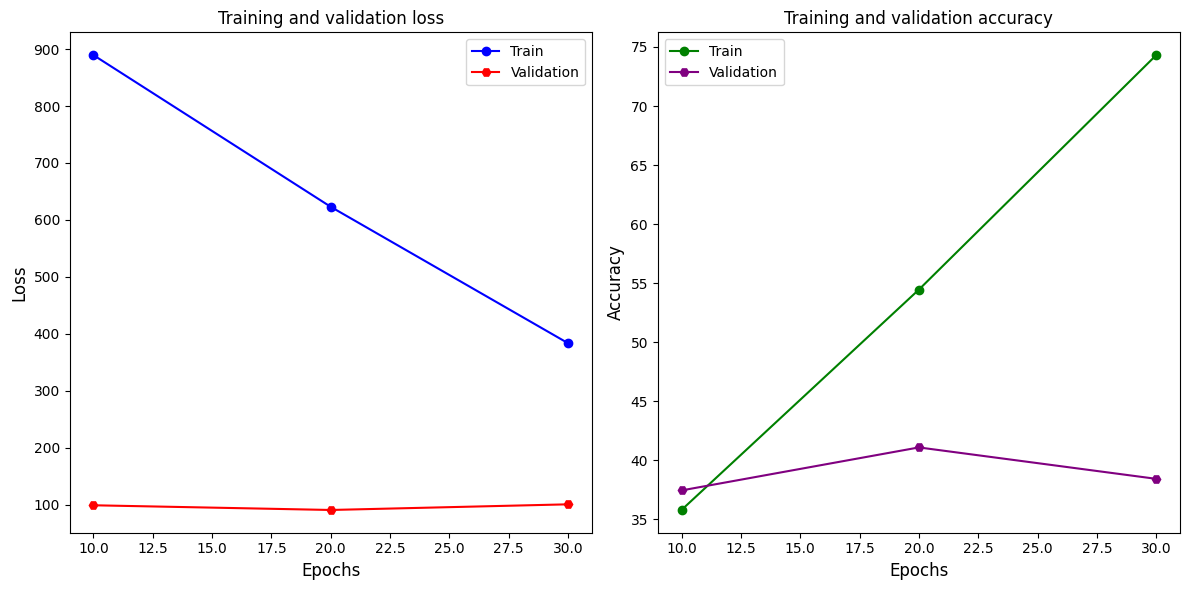

In [33]:
fig, axes = plt.subplots(1, 2, figsize = (12, 6))

axes[0].plot(epoch_list, tr_loss_list, color = 'b', label = 'Train', marker = 'o')
axes[0].plot(epoch_list, val_loss_list, color = 'r', label = 'Validation', marker = 'H')
axes[0].set_title('Training and validation loss')
axes[0].set_xlabel('Epochs', fontsize= 12)
axes[0].set_ylabel('Loss', fontsize= 12)
axes[0].legend()

axes[1].plot(epoch_list, tr_acc_list, color = 'g', label = 'Train', marker = 'o')
axes[1].plot(epoch_list, val_acc_list, color = 'purple', label = 'Validation', marker = 'H')
axes[1].set_title('Training and validation accuracy')
axes[1].set_xlabel('Epochs', fontsize= 12)
axes[1].set_ylabel('Accuracy', fontsize=12)
axes[1].legend()

plt.tight_layout()
plt.show()

### Saving the Trained Model

This code saves the trained CNN model's parameters (weights and biases) to Google Drive so that the model can be loaded and reused later without needing to train it again.

**Step-by-step explanation:**

- `import os`: Imports Python's `os` module, which provides functions for working with directories and file paths.

- `MODEL_DIR = '/content/drive/MyDrive/CNN_Model'`: Defines the directory path in Google Drive where the model will be saved.

- `os.makedirs(MODEL_DIR, exist_ok=True)`: Creates the specified directory if it does not already exist. The `exist_ok=True` argument prevents an error if the directory already exists.

- `torch.save(CNN_Model.state_dict(), f'{MODEL_DIR}/CNN_2D_MODEL')`: Saves the model's `state_dict`, which contains its learnable parameters (weights and biases), in the specified directory.

> **Note:** Only the model's parameters are saved, not its complete architecture. To use the saved model later, the CNN architecture must be defined again, and the saved parameters must be loaded into it.

This allows us to reuse the trained model without repeating the training process.

In [34]:
import os

MODEL_DIR = '/content/drive/MyDrive/CNN_Model'
os.makedirs(MODEL_DIR, exist_ok= True)
torch.save(CNN_Model.state_dict(), f'{MODEL_DIR}/CNN_2D_MODEL.pth')

### Loading the Saved Model

This code loads the previously saved model parameters from Google Drive and restores them into the CNN model.

**Step-by-step explanation:**

- `torch.load(...)`: Loads the saved model parameters from the specified file.
  - `MODEL_DIR`: Specifies the directory where the model is stored.
  - `map_location=device`: Ensures that the loaded parameters are mapped to the selected device (CPU or GPU), regardless of the device used when saving the model.
  - `weights_only=True`: Loads only the model weights, rather than arbitrary Python objects.

- `CNN_Model.load_state_dict(state)`: Loads the saved weights and biases into the existing CNN model architecture.

> **Important:** The CNN architecture must be defined before loading the parameters. Its structure must match the architecture used when the model was saved.

After loading the parameters, the model can be used for inference or further evaluation without training it from scratch.

In [36]:
state = torch.load(f'{MODEL_DIR}/CNN_2D_MODEL.pth', map_location= device, weights_only= True)

CNN_Model.load_state_dict(state)

<All keys matched successfully>

### Verifying and Preparing the Loaded Model

This code checks the model's parameters and switches the model to evaluation mode after loading the saved weights.

**Step-by-step explanation:**

- `CNN_Model.state_dict().keys()`: Displays the names of all parameters and buffers stored in the model's `state_dict`, such as layer weights and biases. This helps verify the model's structure and its available parameters.

- `CNN_Model.eval()`: Switches the model to evaluation mode. This is important when using the model for inference or validation because certain layers, such as Dropout and Batch Normalization, behave differently during evaluation compared to training.

- `print(...)`: Displays a confirmation message indicating that the model parameters have been loaded successfully.

> **Note:** Calling `eval()` does not disable gradient calculations. For inference, it is also recommended to use `torch.no_grad()` or `torch.inference_mode()` to avoid unnecessary gradient computation.

In [37]:
print(CNN_Model.state_dict().keys())
CNN_Model.eval()
print(f'Our model has been loaded successfully')

odict_keys(['Blocks.0.weight', 'Blocks.0.bias', 'Blocks.1.weight', 'Blocks.1.bias', 'Blocks.1.running_mean', 'Blocks.1.running_var', 'Blocks.1.num_batches_tracked', 'Blocks.4.weight', 'Blocks.4.bias', 'Blocks.5.weight', 'Blocks.5.bias', 'Blocks.5.running_mean', 'Blocks.5.running_var', 'Blocks.5.num_batches_tracked', 'Blocks.8.weight', 'Blocks.8.bias', 'Blocks.9.weight', 'Blocks.9.bias', 'Blocks.9.running_mean', 'Blocks.9.running_var', 'Blocks.9.num_batches_tracked', 'FC.1.weight', 'FC.1.bias', 'FC.4.weight', 'FC.4.bias'])
Our model has been loaded successfully


`CNN_Model.state_dict()` returns a Python dictionary containing the model's learnable parameters (weights and biases) and registered buffers.

Each entry in this dictionary consists of:

- Key: The name of a parameter or buffer, identifying the layer it belongs to.
- Value: The corresponding tensor containing its numerical values.

For example, in a CNN model, the dictionary may contain entries such as:

- `conv1.weight`: Weights of the first convolutional layer.
- `conv1.bias`: Biases of the first convolutional layer.
- `fc.weight`: Weights of a fully connected layer.
- `fc.bias`: Biases of a fully connected layer.

By calling `CNN_Model.state_dict()` directly, we can inspect the actual tensors stored in the model.

> Note: Unlike `CNN_Model.state_dict().keys()`, which displays only the parameter names, `CNN_Model.state_dict()` displays both the names and their corresponding tensor values.

In [38]:
CNN_Model.state_dict()

OrderedDict([('Blocks.0.weight',
              tensor([[[[ 0.1515,  0.1519, -0.0699],
                        [ 0.1839, -0.0004,  0.0416],
                        [-0.1022,  0.1067,  0.1604]],
              
                       [[-0.1316,  0.1418,  0.0121],
                        [ 0.1277,  0.0294,  0.0782],
                        [-0.0535,  0.1139,  0.0154]],
              
                       [[-0.0721,  0.0499, -0.0793],
                        [-0.0297, -0.0750,  0.1211],
                        [-0.1675, -0.1038, -0.0461]]],
              
              
                      [[[-0.2030,  0.0979, -0.2422],
                        [ 0.1809, -0.2909,  0.1346],
                        [-0.0283, -0.1258,  0.1869]],
              
                       [[-0.0573,  0.2934, -0.0786],
                        [ 0.0553,  0.0247, -0.0554],
                        [ 0.0891,  0.1669,  0.1469]],
              
                       [[-0.1494,  0.2205, -0.0278],
                       

## we incline to implement predictions on our unseen data
### Evaluating the Model on the Test Dataset

This code evaluates the trained CNN model on the test dataset to measure its performance on previously unseen data. It calculates the average test loss and test accuracy without updating the model's parameters.

**Step-by-step explanation:**

- `CNN_Model.eval()`: Switches the model to evaluation mode. This ensures that layers such as Dropout and Batch Normalization behave appropriately during testing.

- `test_loss, test_correct, test_total = 0, 0, 0`: Initializes three variables:
  - `test_loss`: Accumulates the loss across all test batches.
  - `test_correct`: Counts the number of correctly classified samples.
  - `test_total`: Counts the total number of test samples.

- `with torch.no_grad():`: Disables gradient calculation during testing. Since no training or backpropagation is performed, this reduces memory usage and computational overhead.

- `for x, y in TestLoader:`: Iterates through the test dataset batch by batch, where `x` contains the input images and `y` contains their corresponding ground-truth labels.

- `x, y = x.to(device), y.to(device)`: Moves the input images and labels to the selected device (CPU or GPU).

- `te_out = CNN_Model(x)`: Passes the input images through the CNN model to obtain the predicted class scores (logits).

- `_, te_pre = torch.max(te_out, dim=1)`: Finds the class with the highest predicted score for each sample. The predicted class indices are stored in `te_pre`.

- `testloss = loss(te_out, y)`: Calculates the loss for the current test batch using the specified loss function.

- `test_loss += testloss.item()`: Adds the current batch loss to the accumulated test loss.

- `test_total += te_out.size(0)`: Updates the total number of processed test samples using the batch size.

- `test_correct += (te_pre == y).sum().item()`: Compares the predicted labels with the actual labels and adds the number of correct predictions to the counter.

- `test_accuracy = 100 * (test_correct / test_total)`: Calculates the overall test accuracy as a percentage.

> **Note:** If `loss` uses its default `reduction='mean'` (as in `CrossEntropyLoss`), the accumulated `test_loss` should be divided by `test_total` after the loop to obtain the average loss per sample, assuming equal sample weighting within each batch.

In [39]:
CNN_Model.eval()
test_loss, test_correct, test_total = 0, 0, 0

with torch.no_grad():
  for x, y in TestLoader:
    x, y = x.to(device), y.to(device)

    te_out = CNN_Model(x)

    _, te_pre = torch.max(te_out, dim= 1)

    testloss = loss(te_out, y)

    test_loss += testloss.item()
    test_total += te_out.size(0)
    test_correct += (te_pre == y).sum().item()

test_accuracy = 100 * (test_correct/ test_total)

In [40]:
test_accuracy

37.88

### Displaying Random Test Predictions

This code selects a random batch of test images, generates predictions using the trained CNN model, and compares the predicted classes with the actual labels. It also displays the overall test loss and accuracy.

**Step-by-step explanation:**

- `class_name = classes = [...]`: Defines a list containing the names of the 100 CIFAR-100 classes. Each class name corresponds to a numerical label (index) used by the dataset.

- `CNN_Model.eval()`: Switches the model to evaluation mode to ensure that layers such as Dropout and Batch Normalization behave appropriately during inference.

- `Image, Label = next(iter(TestLoader))`: Creates an iterator from the test DataLoader and retrieves the first batch of test images and their corresponding labels.

- `with torch.no_grad():`: Disables gradient calculation because the model is only being used to make predictions.

- `out = CNN_Model(Image.to(device))`: Moves the input images to the selected device and passes them through the model to obtain class scores (logits).

- `pred = out.argmax(dim=1)`: Selects the class with the highest predicted score for each image and stores the predicted class indices.

**Selecting random samples:**

- `import random`: Imports Python's random module.
- `rand_list = []`: Creates an empty list to store randomly selected sample indices.
- `for i in range(10):`: Repeats the selection process 10 times.
- `a = random.randint(0, 127)`: Generates a random integer between 0 and 127 (inclusive), assuming the test batch contains 128 samples.
- `rand_list.append(a)`: Adds the selected index to the list.
- `rand_list`: Displays the selected indices.

**Displaying the results:**

- `print(...)`: Displays the overall test loss and test accuracy, with accuracy formatted to two decimal places.
- `for i in rand_list:`: Iterates through the randomly selected sample indices.
- `class_name[Label[i].item()]`: Retrieves the actual class name corresponding to the sample's numerical label.
- `class_name[pred[i].item()]`: Retrieves the predicted class name.
- `print(...)`: Displays the sample index, actual class, and predicted class for each selected image.

This comparison provides a simple way to inspect individual predictions and see whether the model correctly classifies unseen images.

> **Note:** The random indices are selected with replacement, so the same sample may occasionally appear more than once. Also, the code assumes that the batch contains 128 samples. If you want 10 unique random samples, you can use `random.sample(range(len(Label)), 10)` instead.

In [41]:
class_name = classes = [
    'apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle',
    'bowl', 'boy', 'bridge', 'bus', 'butterfly', 'camel', 'can', 'castle', 'caterpillar', 'cattle',
    'chair', 'chimpanzee', 'clock', 'cloud', 'cockroach', 'couch', 'crab', 'crocodile', 'cup', 'dinosaur',
    'dolphin', 'elephant', 'flatfish', 'forest', 'fox', 'girl', 'hamster', 'house', 'kangaroo', 'keyboard',
    'lamp', 'lawn_mower', 'leopard', 'lion', 'lizard', 'lobster', 'man', 'maple_tree', 'motorcycle', 'mountain',
    'mouse', 'mushroom', 'oak_tree', 'orange', 'orchid', 'otter', 'palm_tree', 'pear', 'pickup_truck', 'pine_tree',
    'plain', 'plate', 'poppy', 'porcupine', 'possum', 'rabbit', 'raccoon', 'ray', 'road', 'rocket',
    'rose', 'sea', 'seal', 'shark', 'shrew', 'skunk', 'skyscraper', 'snail', 'snake', 'spider',
    'squirrel', 'streetcar', 'sunflower', 'sweet_pepper', 'table', 'tank', 'telephone', 'television', 'tiger', 'tractor',
    'train', 'trout', 'tulip', 'turtle', 'wardrobe', 'whale', 'willow_tree', 'wolf', 'woman', 'worm'
]

CNN_Model.eval()

Image, Label = next(iter(TestLoader))

with torch.no_grad():
  out = CNN_Model(Image.to(device))

  pred = out.argmax(dim = 1)

import random
rand_list = []
for i in range(10):
  a = random.randint(0, 127)
  rand_list.append(a)
rand_list

print(f'Test Loss: {test_loss}| Test Accuracy: {test_accuracy: .2f}%')
for i in rand_list:
  print(f'Counter: {i} | Actual label: {class_name[Label[i].item()]} | Predicted label: {class_name[pred[i].item()]}')

Test Loss: 196.9757900238037| Test Accuracy:  37.88%
Counter: 43 | Actual label: shark | Predicted label: dolphin
Counter: 56 | Actual label: sea | Predicted label: sea
Counter: 17 | Actual label: wolf | Predicted label: wolf
Counter: 106 | Actual label: skyscraper | Predicted label: skyscraper
Counter: 24 | Actual label: chimpanzee | Predicted label: chimpanzee
Counter: 79 | Actual label: clock | Predicted label: plate
Counter: 99 | Actual label: girl | Predicted label: lion
Counter: 42 | Actual label: mountain | Predicted label: mountain
Counter: 127 | Actual label: mouse | Predicted label: lizard
Counter: 68 | Actual label: porcupine | Predicted label: porcupine
